# Задание 49. Кластеризация студентов RemI AI

## 1. Данные и признаки

Берём 3000 вымышленных студентов из промежуточной аттестации. Попробуем найти группы с похожими результатами первых вопросов по уравнениям и производным. По каждой теме задано два вопроса, поэтому каждый признак принимает значения 0, 1 и 2.

Для кластеризации используем только начальные ответы. После получения групп сравним долю `needs_review = 1` в каждой. Значение 1 означает, что студент правильно решил не больше одного из трёх вопросов дополнительной проверки производных.

Данные смоделированы программой. Таблица лежит рядом с блокнотом. Для запуска нужны pandas, matplotlib, scipy и scikit-learn.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

path = Path("diagnostic_data.csv")
if not path.is_file():
    path = Path("cleaned.csv")

data = pd.read_csv(path).rename(columns={
    "initial_equations_correct": "Уравнения",
    "initial_derivatives_correct": "Производные",
})
features = ["Уравнения", "Производные"]
scaler = StandardScaler()
X = scaler.fit_transform(data[features])

print(f"Студентов: {len(data)}")
print(f"Сочетаний признаков: {len(data[features].drop_duplicates())}")
display(data.groupby(features).size().rename("Студентов").to_frame())

Студентов: 3000
Сочетаний признаков: 9


Студентов
Уравнения Производные           
0         0                  395
          1                  374
          2                  184
1         0                  405
          1                  579
          2                  433
2         0                  107
          1                  237
          2                  286

## 2. Подбор числа кластеров K-Means

Проверяем от двух до девяти кластеров. Строим график суммы квадратов расстояний до центров и график silhouette. Чем выше silhouette, тем чётче разделены группы.

У девяти сочетаний признаков есть особенность. При девяти кластерах каждое сочетание может образовать отдельную группу из совпадающих точек. Это даст silhouette, равный 1. Посмотрим, происходит ли это в наших данных.

,Сумма квадратов расстояний,Silhouette
Кластеров,,
2,3424.3130,0.4387
3,2222.1519,0.5088
4,1420.8010,0.5894
5,947.4375,0.6912
6,583.2244,0.7893
7,326.5935,0.8733
8,122.1849,0.9526
9,0.0000,1.0000


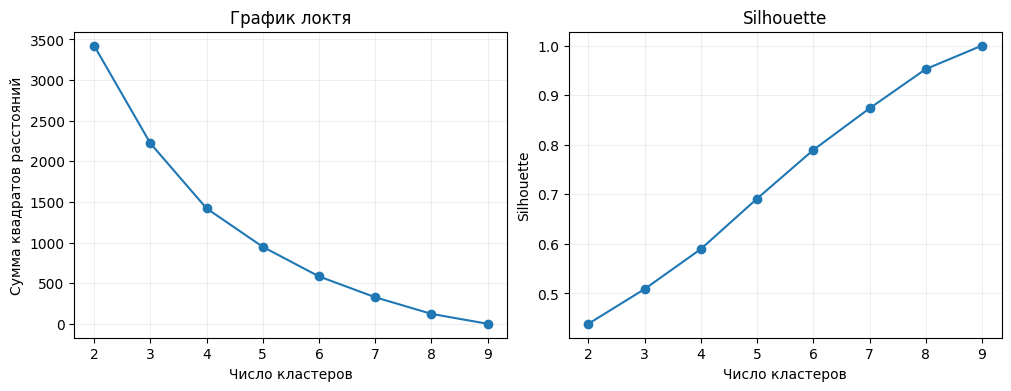

Лучшее число кластеров по silhouette: 9


In [2]:
models = {}
rows = []
for k in range(2, 10):
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    models[k] = model
    rows.append({
        "Кластеров": k,
        "Сумма квадратов расстояний": model.inertia_,
        "Silhouette": silhouette_score(X, labels),
    })

scores = pd.DataFrame(rows).set_index("Кластеров")
display(scores.round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
axes[0].plot(scores.index, scores["Сумма квадратов расстояний"], "o-")
axes[0].set(title="График локтя", xlabel="Число кластеров",
            ylabel="Сумма квадратов расстояний")
axes[1].plot(scores.index, scores["Silhouette"], "o-")
axes[1].set(title="Silhouette", xlabel="Число кластеров", ylabel="Silhouette")
for ax in axes:
    ax.set_xticks(scores.index)
    ax.grid(alpha=0.2)
plt.show()

best_k = int(scores["Silhouette"].idxmax())
print(f"Лучшее число кластеров по silhouette: {best_k}")

По silhouette выбран вариант с девятью кластерами. Здесь алгоритм выделяет девять типов начальных ответов. На графике локтя нет одного очевидного перелома.

## 3. Иерархическая кластеризация

Для сравнения используем то же число групп. Пробуем четыре правила объединения: single, complete, average и Ward. Оцениваем silhouette и совпадение с K-Means через ARI. ARI равен 1, если разбиения совпадают с точностью до номеров групп.

Чтобы увидеть, как методы объединяют типы ответов в более крупные группы, дополнительно сравним их при трёх кластерах. Это выбранный для обзора вариант.

,Кластеров,Метод,Silhouette,ARI с K-Means
0,9,K-Means,1.0000,1.0000
1,9,single,1.0000,1.0000
2,9,complete,1.0000,1.0000
3,9,average,1.0000,1.0000
4,9,ward,1.0000,1.0000
5,3,K-Means,0.5088,1.0000
6,3,single,0.4420,0.3920
7,3,complete,0.4837,0.0741
8,3,average,0.4075,0.2978
9,3,ward,0.5004,0.2716


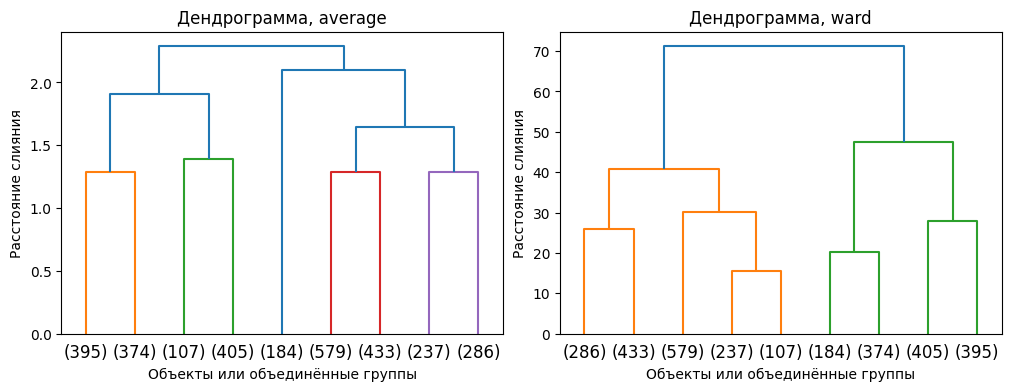

In [3]:
labels_by_method = {}
comparison = []

for k in [best_k, 3]:
    kmeans_labels = models[k].labels_
    labels_by_method[(k, "K-Means")] = kmeans_labels
    comparison.append({
        "Кластеров": k, "Метод": "K-Means",
        "Silhouette": silhouette_score(X, kmeans_labels),
        "ARI с K-Means": 1.0,
    })
    for method in ["single", "complete", "average", "ward"]:
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        labels_by_method[(k, method)] = labels
        comparison.append({
            "Кластеров": k, "Метод": method,
            "Silhouette": silhouette_score(X, labels),
            "ARI с K-Means": adjusted_rand_score(kmeans_labels, labels),
        })

display(pd.DataFrame(comparison).round(4))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), layout="constrained")
for ax, method in zip(axes, ["average", "ward"]):
    tree = linkage(X, method=method)
    dendrogram(tree, truncate_mode="lastp", p=9, ax=ax)
    ax.set_title(f"Дендрограмма, {method}")
    ax.set_xlabel("Объекты или объединённые группы")
    ax.set_ylabel("Расстояние слияния")
plt.show()

При девяти группах все методы выделили одинаковые типы ответов. При трёх группах результат зависит от правила объединения. Для этого варианта сравним группы на графиках. Номер кластера служит меткой и сам по себе ничего не говорит об уровне подготовки.

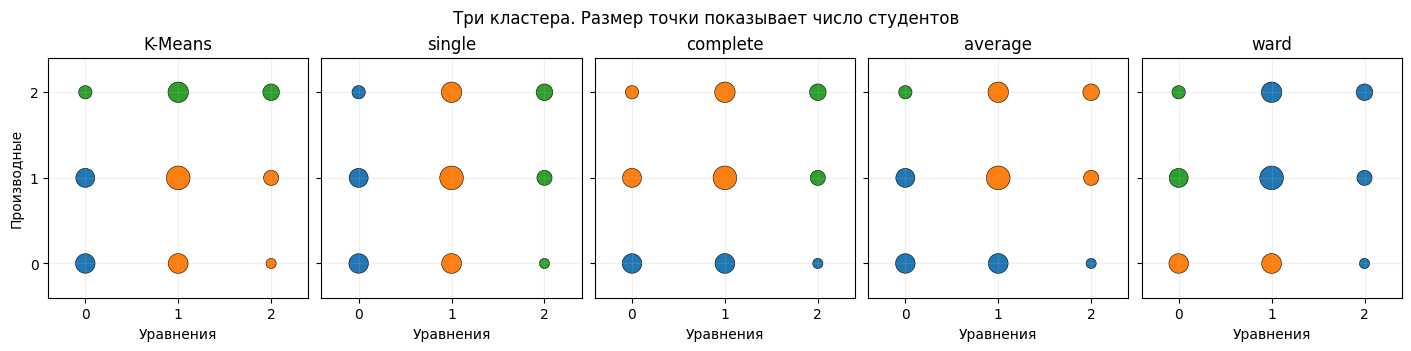

In [4]:
fig, axes = plt.subplots(1, 5, figsize=(14, 3.4), sharey=True, layout="constrained")
for ax, method in zip(axes, ["K-Means", "single", "complete", "average", "ward"]):
    chart = data[features].copy()
    chart["Кластер"] = labels_by_method[(3, method)]
    points = chart.groupby(features + ["Кластер"]).size().reset_index(name="Студентов")
    ax.scatter(points["Уравнения"], points["Производные"],
               c=points["Кластер"], s=points["Студентов"] * 0.5,
               cmap="tab10", vmin=0, vmax=9, edgecolors="black", linewidths=0.4)
    ax.set_title(method)
    ax.set_xlabel("Уравнения")
    ax.set_xticks([0, 1, 2])
    ax.set_yticks([0, 1, 2])
    ax.set_xlim(-0.4, 2.4)
    ax.set_ylim(-0.4, 2.4)
    ax.grid(alpha=0.2)
axes[0].set_ylabel("Производные")
fig.suptitle("Три кластера. Размер точки показывает число студентов")
plt.show()

## 4. Сопоставление с результатом дополнительной проверки

Теперь добавляем `needs_review`. Сначала опишем девять типов начальных ответов, затем три крупные группы K-Means.

,Студентов,Уравнения,Производные,Доля_затруднений
Кластер,,,,
0,395,0.0,0.0,0.775
5,374,0.0,1.0,0.612
7,184,0.0,2.0,0.397
4,405,1.0,0.0,0.721
3,579,1.0,1.0,0.520
1,433,1.0,2.0,0.256
8,107,2.0,0.0,0.523
2,237,2.0,1.0,0.376
6,286,2.0,2.0,0.210


,Студентов,Уравнения,Производные,Доля_затруднений
Кластер,,,,
0,769,0.000,0.486,0.696
1,1328,1.259,0.614,0.556
2,903,1.113,2.000,0.270


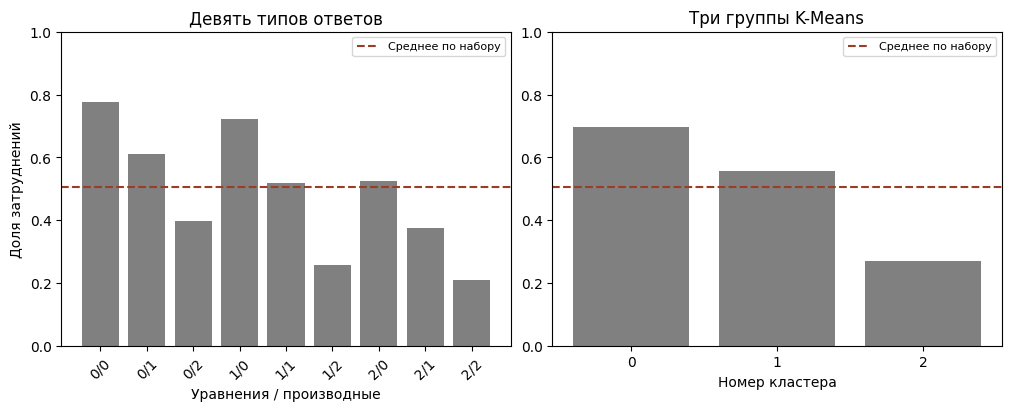

In [5]:
profiles = data[features + ["needs_review"]].copy()
profiles["Кластер"] = labels_by_method[(best_k, "K-Means")]
summary9 = profiles.groupby("Кластер").agg(
    Студентов=("needs_review", "size"),
    Уравнения=("Уравнения", "mean"),
    Производные=("Производные", "mean"),
    Доля_затруднений=("needs_review", "mean"),
).sort_values(["Уравнения", "Производные"])
display(summary9.round(3))

profiles["Кластер"] = labels_by_method[(3, "K-Means")]
summary3 = profiles.groupby("Кластер").agg(
    Студентов=("needs_review", "size"),
    Уравнения=("Уравнения", "mean"),
    Производные=("Производные", "mean"),
    Доля_затруднений=("needs_review", "mean"),
)
display(summary3.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")
labels = [f"{int(row.Уравнения)}/{int(row.Производные)}" for row in summary9.itertuples()]
axes[0].bar(labels, summary9["Доля_затруднений"], color="0.5")
axes[0].set(title="Девять типов ответов", xlabel="Уравнения / производные",
            ylabel="Доля затруднений")
axes[0].tick_params(axis="x", rotation=45)
axes[1].bar(summary3.index.astype(str), summary3["Доля_затруднений"], color="0.5")
axes[1].set(title="Три группы K-Means", xlabel="Номер кластера")
for ax in axes:
    ax.set_ylim(0, 1)
    ax.axhline(data["needs_review"].mean(), color="#9b3c24",
               linestyle="--", label="Среднее по набору")
    ax.legend(fontsize=8)
plt.show()

## 5. Интерпретация групп

При девяти кластерах доля затруднений различается от 21% для двух правильных ответов по каждой теме до 77,5% для нуля правильных ответов по обеим темам. Такой результат позволяет сравнить каждый тип начальных ответов с отдельной дополнительной проверкой.

В варианте K-Means с тремя группами получилось следующее.

- Группа 0 — 769 студентов с нулём правильных ответов по уравнениям и в среднем 0,49 по производным. Затруднение на дополнительной проверке отмечено примерно у 70%. Для RemI AI это группа, которой можно предложить дополнительные базовые вопросы и затем уточнить маршрут.
- Группа 1 — 1328 студентов со средними начальными результатами 1,26 по уравнениям и 0,61 по производным. Затруднение отмечено примерно у 56%. Для этой группы имеет смысл подробнее проверить производные.
- Группа 2 — 903 студента, правильно ответивших на оба начальных вопроса по производным. По уравнениям средний результат равен 1,11. Затруднение отмечено примерно у 27%. Даже хорошие начальные результаты сопровождаются ошибками на дополнительной проверке.

## 6. Вывод

По silhouette лучшим оказалось разбиение на девять групп, совпадающих с девятью сочетаниями признаков. На нём K-Means и все четыре иерархических метода дали одинаковые группы.

При объединении в три крупные группы методы расходятся. У K-Means silhouette около 0,509, у Ward — около 0,500. По этим двум признакам нет единственного подтверждённого деления на три типа студентов.

Для RemI AI группы могут помочь организовать дальнейшую проверку знаний. Доли затруднений относятся к синтетическому набору, где связь ответов задана при моделировании. Silhouette оценивает разделение по начальным признакам. Для вывода о знаниях конкретного человека нужны дополнительные ответы.